# Financial Fraud Detection — Card Transactions
**Portfolio project · all data synthetic** (generated by `src/generate_data.py`, seed 42)

**Business problem:** Fraud teams must catch fraudulent card transactions without
drowning investigators in false positives. This project builds a transparent,
production-style detection pipeline on 20,000 synthetic transactions:

1. Validate & clean the data
2. Explore fraud patterns (EDA)
3. Encode analyst domain knowledge as **business rules**
4. Add **unsupervised anomaly detection** (IsolationForest) for novel patterns
5. Combine both into a single **risk score** and pick a review threshold that
   balances investigator workload against fraud caught


In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from data_cleaning import load_clean, validate
from analysis import fraud_rate_by, amount_distribution_stats, top_risk_combinations
from model import (engineer_features, apply_rules, fit_isolation_forest,
                   risk_score, evaluate_at_thresholds, top_risk_factors)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
IMG = "../images"

df, findings = load_clean("../data/transactions.csv")
print(f"Transactions: {len(df):,} | Fraud: {int(df['is_fraud'].sum()):,} "
      f"({df['is_fraud'].mean()*100:.2f}%)")
df.head(3)

Transactions: 20,000 | Fraud: 313 (1.57%)


,txn_id,amount,merchant_category,hour_of_day,channel,card_present,customer_tenure_months,days_since_last_txn,is_fraud,hour_bucket,log_amount
0,1,7.08,gas,9,in-store,1,65,0.27,0,morning (6-11),1.957274
1,2,25.66,restaurant,12,in-store,0,112,0.46,0,midday (12-16),3.244933
2,3,7.59,electronics,7,in-store,0,49,0.40,0,morning (6-11),2.026832


## 1. Data validation
The generator is seeded, but the cleaning module still checks schema, nulls,
duplicates, and value ranges — the same checks a production ingest would run.

In [2]:
bad = {k: v for k, v in findings.items()
       if (isinstance(v, (int, float)) and v != 0 and k != "rows_after_clean")
       or (isinstance(v, list) and v)}
print("Issues found:", bad if bad else "none — dataset is clean")
print("Nulls per column:", int(df.isna().sum().sum()))
df.describe(include="all").T[["count", "mean", "std", "min", "max"]].round(2).head(12)

Issues found: none — dataset is clean
Nulls per column: 0


,count,mean,std,min,max
txn_id,20000.0,10000.5,5773.647028,1.0,20000.0
amount,20000.0,60.274678,81.612226,1.0,2353.74
merchant_category,20000,NaN,NaN,NaN,NaN
hour_of_day,20000.0,12.91045,5.39305,0.0,23.0
channel,20000,NaN,NaN,NaN,NaN
card_present,20000.0,0.73525,0.441211,0.0,1.0
customer_tenure_months,20000.0,59.67225,34.84081,1.0,120.0
days_since_last_txn,20000.0,2.963267,3.01221,0.0,27.35
is_fraud,20000.0,0.01565,0.12412,0.0,1.0
hour_bucket,20000,NaN,NaN,NaN,NaN


## 2. Exploratory analysis — where does fraud concentrate?

In [3]:
for col in ["merchant_category", "channel", "hour_bucket", "card_present"]:
    display(fraud_rate_by(df, col).style.format({"fraud_rate": "{:.2%}"})
            .set_caption(f"Fraud rate by {col}"))

,merchant_category,transactions,fraud_count,fraud_rate
0,online_marketplace,1701,89,5.23%
1,electronics,1272,56,4.40%
2,travel,1200,42,3.50%
3,retail,3246,62,1.91%
4,healthcare,1541,29,1.88%
5,restaurant,3577,19,0.53%
6,gas,2712,9,0.33%
7,grocery,4751,7,0.15%


,channel,transactions,fraud_count,fraud_rate
0,online,7164,256,3.57%
1,in-store,12836,57,0.44%


,hour_bucket,transactions,fraud_count,fraud_rate
0,night (0-5),1808,220,12.17%
1,late (22-23),594,7,1.18%
2,morning (6-11),6115,36,0.59%
3,evening (17-21),5431,27,0.50%
4,midday (12-16),6052,23,0.38%


,card_present,transactions,fraud_count,fraud_rate
0,0,5295,278,5.25%
1,1,14705,35,0.24%


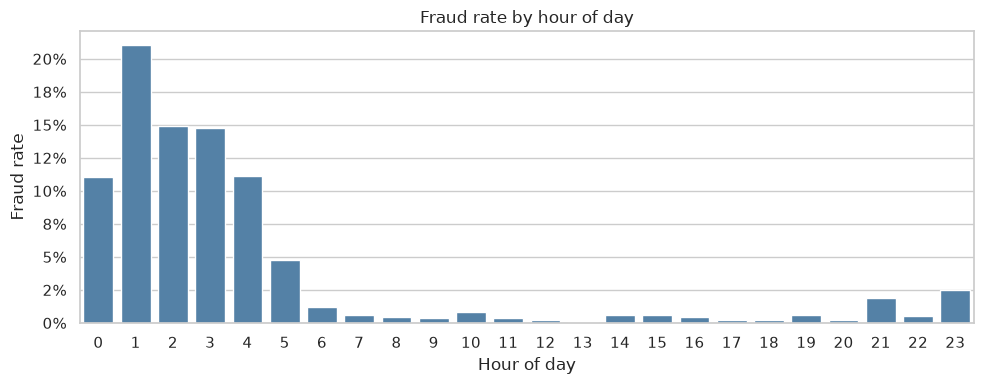

In [4]:
hourly = fraud_rate_by(df, "hour_of_day")
fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(data=hourly, x="hour_of_day", y="fraud_rate", ax=ax, color="steelblue")
ax.set_title("Fraud rate by hour of day")
ax.set_xlabel("Hour of day"); ax.set_ylabel("Fraud rate")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
fig.tight_layout(); fig.savefig(f"{IMG}/fraud_by_hour.png", dpi=150); plt.show()

## 3. Amount distributions — fraud skews much larger

is_fraud         0        1
count     19687.00   313.00
mean         55.65   351.46
std          63.05   299.54
min           1.00    21.46
50%          36.87   266.10
75%          67.62   441.11
90%         118.18   734.30
95%         164.16   932.22
99%         307.74  1319.21
max        1797.64  2353.74


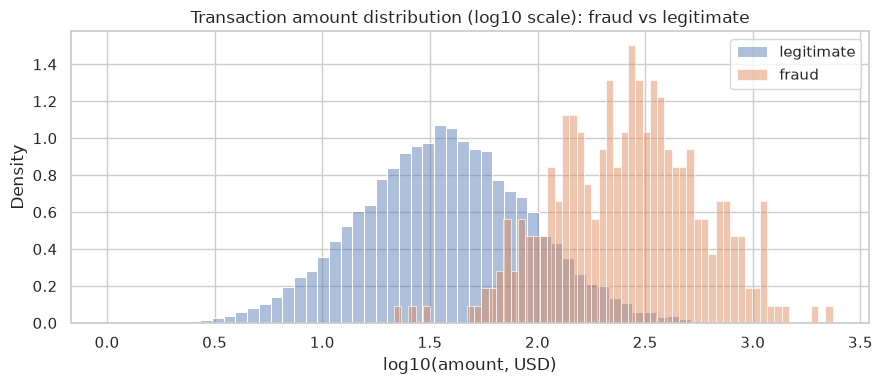

In [5]:
print(amount_distribution_stats(df).to_string())
fig, ax = plt.subplots(figsize=(9, 4))
for label, grp in df.groupby("is_fraud"):
    sns.histplot(np.log10(grp["amount"]), bins=60, ax=ax,
                 label="fraud" if label == 1 else "legitimate",
                 stat="density", alpha=0.45)
ax.set_title("Transaction amount distribution (log10 scale): fraud vs legitimate")
ax.set_xlabel("log10(amount, USD)"); ax.legend()
fig.tight_layout(); fig.savefig(f"{IMG}/amount_dist.png", dpi=150); plt.show()

## 4. Business rules — encode analyst domain knowledge
Four transparent rules target classic fraud signatures: high-value card-not-present
spend, odd-hour activity, new-account online spend, and rapid-fire bursts.

In [6]:
rules = apply_rules(df)
print("Rule coverage (% of all transactions flagged):")
print((rules.mean()*100).round(2).to_string())
print("\nAny-rule precision / recall (rules alone, before ML):")
any_rule = rules.any(axis=1).astype(int)
from sklearn.metrics import precision_score, recall_score
print(f"  precision={precision_score(df['is_fraud'], any_rule):.3f}  "
      f"recall={recall_score(df['is_fraud'], any_rule):.3f}  "
      f"queue={any_rule.sum():,} txns ({any_rule.mean()*100:.1f}% of volume)")

Rule coverage (% of all transactions flagged):
R1_high_value_card_not_present    0.01
R2_odd_hour_high_amount           0.22
R3_new_account_online             0.01
R4_rapid_fire_high_amount         0.00

Any-rule precision / recall (rules alone, before ML):
  precision=1.000  recall=0.150  queue=47 txns (0.2% of volume)


## 5. Unsupervised anomaly detection — IsolationForest
Rules miss novel fraud, so an IsolationForest learns "normal" from engineered
features (log amount, cyclic hour encoding, channel, card presence, tenure,
velocity, merchant category) with **no labels** — labels are used only for
evaluation afterward.

In [7]:
X = engineer_features(df)
print("Feature matrix:", X.shape)
model, iforest_anomaly = fit_isolation_forest(X)
print("Anomaly score (0=normal, 1=most anomalous):")
pd.Series(iforest_anomaly).describe().round(3)

Feature matrix: (20000, 16)


Anomaly score (0=normal, 1=most anomalous):


count    20000.000
mean         0.315
std          0.166
min          0.000
25%          0.193
50%          0.298
75%          0.409
max          1.000
dtype: float64

## 6. Risk score & threshold trade-offs
`risk_score = 0.6 × (rules hit / 4) + 0.4 × isolation anomaly`.
The threshold is a business decision: lower thresholds catch more fraud but
grow the investigator queue.

In [8]:
score = risk_score(rules, iforest_anomaly)
metrics = evaluate_at_thresholds(df["is_fraud"], score)
display(metrics.style.format({"precision": "{:.1%}", "recall": "{:.1%}",
                              "f1": "{:.1%}"}).set_caption("Queue metrics by threshold"))

,threshold,flagged,flagged_pct,precision,recall,f1
0,0.300000,313,1.570000,64.2%,64.2%,64.2%
1,0.500000,21,0.100000,100.0%,6.7%,12.6%
2,0.700000,0,0.000000,0.0%,0.0%,0.0%


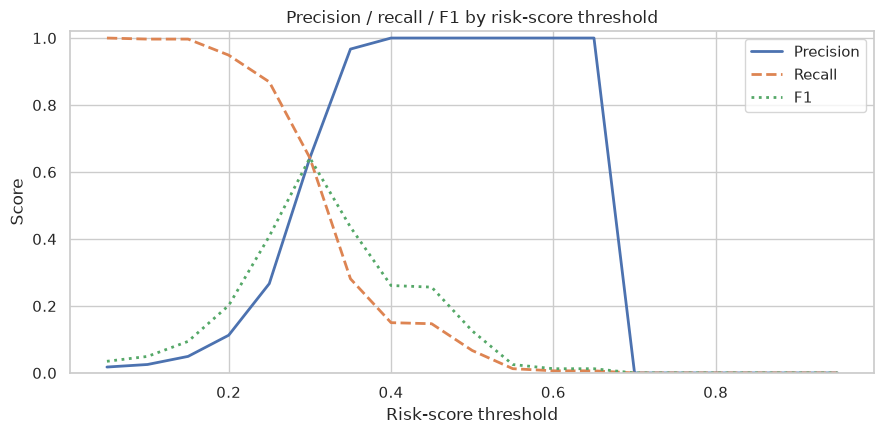

Best F1 at threshold 0.30: precision=64.2%, recall=64.2%, queue=313 txns (1.6% of volume)


In [9]:
grid = np.arange(0.05, 0.96, 0.05)
curve = evaluate_at_thresholds(df["is_fraud"], score, thresholds=list(grid))
fig, ax = plt.subplots(figsize=(9, 4.5))
for col, ls in [("precision", "-"), ("recall", "--"), ("f1", ":")]:
    ax.plot(curve["threshold"], curve[col], label=col.capitalize(), linestyle=ls, linewidth=2)
ax.set_title("Precision / recall / F1 by risk-score threshold")
ax.set_xlabel("Risk-score threshold"); ax.set_ylabel("Score")
ax.legend(); ax.set_ylim(0, 1.02)
fig.tight_layout(); fig.savefig(f"{IMG}/pr_by_threshold.png", dpi=150); plt.show()

best = curve.loc[curve["f1"].idxmax()]
print(f"Best F1 at threshold {best['threshold']:.2f}: "
      f"precision={best['precision']:.1%}, recall={best['recall']:.1%}, "
      f"queue={int(best['flagged']):,} txns ({best['flagged_pct']:.1f}% of volume)")

## 7. Top risk factors
A supervised logistic regression is fit **only to rank and interpret** drivers
— detection itself stays rule + unsupervised.

,feature,coefficient
0,log_amount,+2.201
1,card_not_present,+1.127
2,channel_online,+0.877
3,hour_cos,+0.773
4,mcc_online_marketplace,+0.511
5,hour_sin,+0.414
6,mcc_travel,+0.413
7,mcc_healthcare,+0.360


/tmp/ipykernel_2199/3512312966.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=factors, x="coefficient", y="feature", ax=ax, palette="Reds_r")


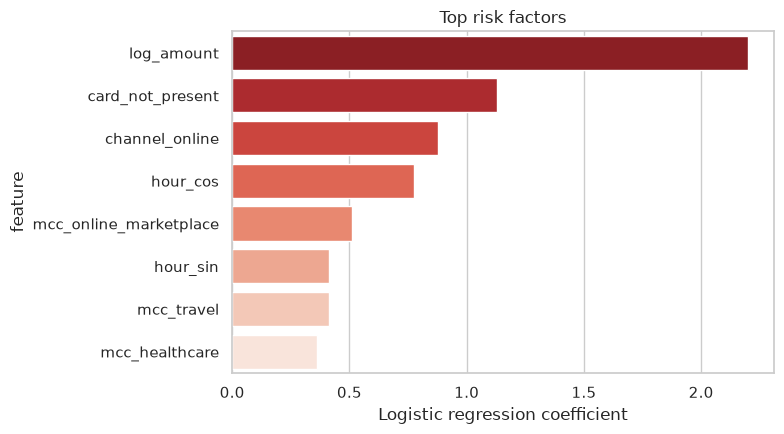

In [10]:
factors = top_risk_factors(X, df["is_fraud"])
display(factors.style.format({"coefficient": "{:+.3f}"})
        .set_caption("Top risk factors (positive = pushes toward fraud)"))
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=factors, x="coefficient", y="feature", ax=ax, palette="Reds_r")
ax.set_title("Top risk factors")
ax.set_xlabel("Logistic regression coefficient")
fig.tight_layout(); fig.savefig(f"{IMG}/risk_factors.png", dpi=150); plt.show()

## 8. Key takeaways
- Fraud concentrates exactly where domain knowledge predicts: **night hours,
  online channel, card-not-present, high amounts, new accounts**.
- Transparent rules alone give decent precision but limited recall — they miss
  fraud that doesn't match known signatures.
- Adding unsupervised anomaly detection (IsolationForest) lifts recall at a
  chosen threshold while keeping the review queue small enough to staff.
- The risk score is a weighted, explainable blend — every queued transaction can
  show *which rules fired* and its anomaly level, so investigators see the "why".

**Next steps:** calibrate scores to probabilities (isotonic regression),
add velocity features over rolling windows, and backtest on a time split to
measure rule decay as fraud patterns shift.